# imports

In [6]:
!pip install pymorphy3
!pip install trl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [7]:
# %%capture cap --no-stderr

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from typing import List
from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import nltk
import pickle
import pymorphy3
import re
from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

import datasets
import gc
import peft
import torch
import trl
from torch.nn.utils.rnn import pad_sequence
from transformers import T5ForConditionalGeneration, AutoTokenizer
from transformers import AutoModelForSeq2SeqLM

# nltk.download('punkt')
# nltk.download('stopwords')
# nltk.download('punkt_tab')

# Data transformers

In [8]:
df = pd.read_csv('comments.csv')
df.head()

,comment,toxic
0,"Верблюдов-то за что? Дебилы, бл...\n",1.0
1,"Хохлы, это отдушина затюканого россиянина, мол...",1.0
2,Собаке - собачья смерть\n,1.0
3,"Страницу обнови, дебил. Это тоже не оскорблени...",1.0
4,"тебя не убедил 6-страничный пдф в том, что Скр...",1.0


In [9]:
class LemmatizeTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        self.morph = pymorphy3.MorphAnalyzer()
        self.stopwords = stopwords.words("russian") + ['это', 'её', '']
        return self

    def transform(self, X):
        def clean_text(text):
            text = text.lower()
            text = re.sub(r'http\S+', '', text)
            text = re.sub(r'www\S+', '', text)
            text = re.sub(r"\'s", " ", text)
            text = re.sub('\W', ' ', text)
            text = re.sub('\s+', ' ', text)
            text = text.strip(' ')
            return text


        X_copy = X.copy()

        if isinstance(X_copy, list):
            X_copy = map(clean_text, X_copy)
            X_copy = map(lambda x: list(map(lambda word: self.morph.parse(word)[0].normal_form, word_tokenize(x))), X_copy)
            X_copy = map(lambda x: [word for word in x if word not in self.stopwords], X_copy)
            X_copy = map(lambda x: ' '.join(x), X_copy)
            X_copy = list(X_copy)
        else:
            X_copy['comment'] = X_copy['comment'].apply(clean_text)
            X_copy['comment'] = X_copy['comment'].apply(lambda x: list(map(lambda word: self.morph.parse(word)[0].normal_form, word_tokenize(x))))
            X_copy['comment'] = X_copy['comment'].apply(lambda x: [word for word in x if word not in self.stopwords])
            X_copy['comment'] = X_copy['comment'].apply(lambda x: ' '.join(x))

        return X_copy

In [ ]:
# lemmatizer = LemmatizeTransformer()
# lemmatizer.fit(df)
# df = lemmatizer.transform(df)
# df

In [ ]:
# df = df[df['comment'] != '']

In [ ]:
# df.isna().value_counts()

In [ ]:
# df.to_csv('comments_lemmatized.csv')

# BoW + LogisticRegression [roc-auc 0.9162]

In [10]:
df = pd.read_csv('comments_lemmatized.csv', index_col=0)

In [11]:
RANDOM_STATE=42


X = df.drop(columns=['toxic'])
y = df['toxic']
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=RANDOM_STATE, test_size=0.25)

In [12]:
class CountTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        assert X.shape[1] == 1
        self.vectorizer_ = CountVectorizer()
        self.vectorizer_.fit(X[X.columns[0]].astype('str'))
        return self

    def transform(self, X):
        assert X.shape[1] == 1
        return self.vectorizer_.transform(X[X.columns[0]].astype('str'))


def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

In [13]:
count_transformer = Pipeline(steps=[
    ('count_transformer', CountTransformer())
])

comment_transformer = ColumnTransformer(transformers=[
    ('comments', count_transformer, ['comment'])
])

preprocessor = Pipeline(steps=[('comment_transformer', comment_transformer)])

lr_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', LogisticRegression())])


lr_pipeline.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('comment_transformer',
                                  ColumnTransformer(transformers=[('comments',
                                                                   Pipeline(steps=[('count_transformer',
                                                                                    CountTransformer())]),
                                                                   ['comment'])]))])),
                ('model', LogisticRegression())])

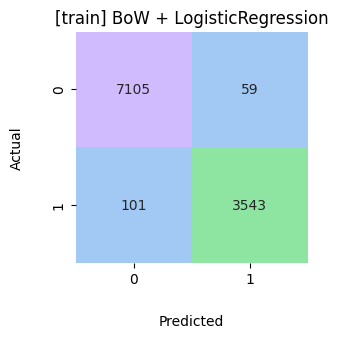

accuracy:	0.9851961509992598
precision:	0.9851869656703359
recall:		0.9851961509992598
f1:		0.9851748812311878


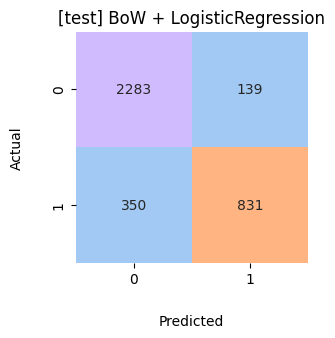

accuracy:	0.8642797668609492
precision:	0.8636724317747787
recall:		0.8642797668609492
f1:		0.8604556416968637


In [14]:
y_pred = lr_pipeline.predict(Xtrain)
get_metrics(ytrain, y_pred, '[train] BoW + LogisticRegression')
y_pred = lr_pipeline.predict(Xtest)
get_metrics(ytest, y_pred, '[test] BoW + LogisticRegression')

In [15]:
y_prob = lr_pipeline.predict_proba(Xtrain)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = lr_pipeline.predict_proba(Xtest)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9983837577324358
roc_auc/test:	0.916262932713183


# Boosting [roc-auc 0.8756], Bagging [roc-auc 0.8913]

##  RandomForest

In [16]:
from sklearn.ensemble import RandomForestClassifier


count_transformer = Pipeline(steps=[
    ('count_transformer', CountTransformer())
])

comment_transformer = ColumnTransformer(transformers=[
    ('comments', count_transformer, ['comment'])
])

preprocessor = Pipeline(steps=[('comment_transformer', comment_transformer)])

rf_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', RandomForestClassifier(random_state=RANDOM_STATE))])


rf_pipeline.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('comment_transformer',
                                  ColumnTransformer(transformers=[('comments',
                                                                   Pipeline(steps=[('count_transformer',
                                                                                    CountTransformer())]),
                                                                   ['comment'])]))])),
                ('model', RandomForestClassifier(random_state=42))])

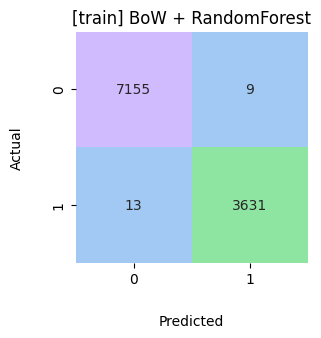

accuracy:	0.9979644707623982
precision:	0.9979642269017761
recall:		0.9979644707623982
f1:		0.9979641959119185


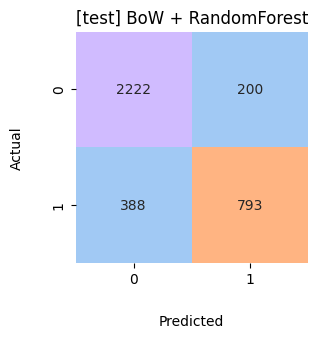

accuracy:	0.8368026644462948
precision:	0.834050190766748
recall:		0.8368026644462948
f1:		0.8327948927873798


In [17]:
y_pred = rf_pipeline.predict(Xtrain)
get_metrics(ytrain, y_pred, '[train] BoW + RandomForest')
y_pred = rf_pipeline.predict(Xtest)
get_metrics(ytest, y_pred, '[test] BoW + RandomForest')

In [18]:
y_prob = rf_pipeline.predict_proba(Xtrain)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = rf_pipeline.predict_proba(Xtest)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9999894275622533
roc_auc/test:	0.8989647186984117


### hyperparameters

In [19]:
ct = CountTransformer()
ct.fit(Xtrain)
Xtrain_ = ct.transform(Xtrain)
Xtest_ = ct.transform(Xtest)

In [22]:
import numpy as np
from sklearn.model_selection import GridSearchCV


params = {
    'n_estimators': np.arange(10, 150, 20),
    'max_depth': list(np.arange(2, 10, 3)) + [None],
}

clf = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), params, cv=3, verbose=2, scoring='roc_auc')
clf.fit(Xtrain_, ytrain)

Fitting 3 folds for each of 28 candidates, totalling 84 fits
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.3s
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=10; total time=   0.1s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=30; total time=   0.4s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.6s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.6s
[CV] END .......................max_depth=2, n_estimators=50; total time=   0.3s
[CV] END .......................max_depth=2, n_estimators=70; total time=   0.5s
[CV] END .......................max_depth=2, n_estimators=70; total time=   0.5s
[CV] END .......................max_depth=2, n_e

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [np.int64(2), np.int64(5), np.int64(8),
                                       None],
                         'n_estimators': array([ 10,  30,  50,  70,  90, 110, 130])},
             scoring='roc_auc', verbose=2)

In [23]:
best_params = clf.best_params_
clf.best_score_, clf.best_estimator_, best_params

(np.float64(0.8836252799387658),
 RandomForestClassifier(max_depth=np.int64(8), n_estimators=np.int64(130),
                        random_state=42),
 {'max_depth': np.int64(8), 'n_estimators': np.int64(130)})

In [24]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, **best_params)
rf.fit(Xtrain_, ytrain)

RandomForestClassifier(max_depth=np.int64(8), n_estimators=np.int64(130),
                       random_state=42)

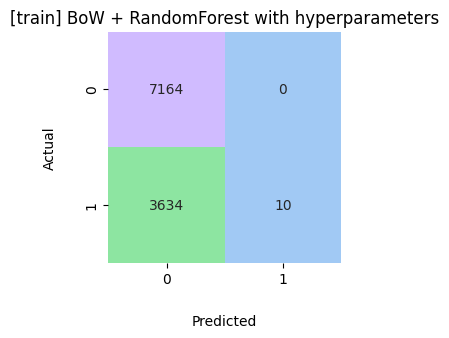

accuracy:	0.6637675795706883
precision:	0.7769245175073544
recall:		0.6637675795706883
f1:		0.5305841449178174


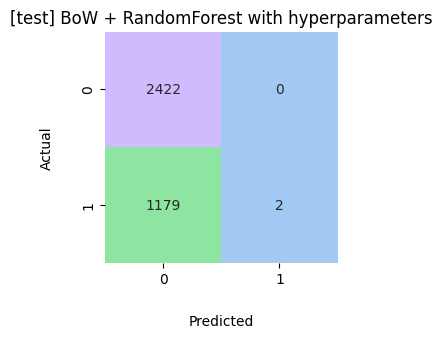

accuracy:	0.6727726894254787
precision:	0.7799098733097778
recall:		0.6727726894254787
f1:		0.5417395621186148


In [25]:
y_pred = rf.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + RandomForest with hyperparameters')
y_pred = rf.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + RandomForest with hyperparameters')

In [26]:
y_prob = rf.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = rf.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.915864923470873
roc_auc/test:	0.8768797314484569


## GradientBoosting

In [27]:
from sklearn.ensemble import GradientBoostingClassifier


gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(Xtrain_, ytrain)

GradientBoostingClassifier(random_state=42)

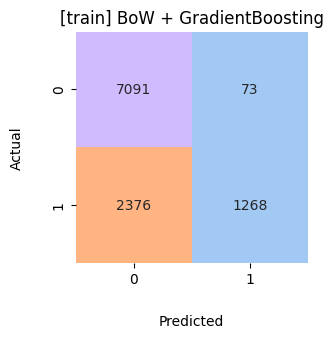

accuracy:	0.7734085862324205
precision:	0.8152879190835995
recall:		0.7734085862324205
f1:		0.7367563353199219


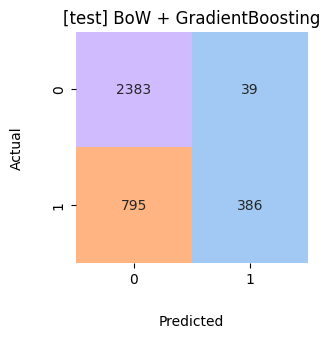

accuracy:	0.768526228143214
precision:	0.8017609839256783
recall:		0.768526228143214
f1:		0.7296693342928215


In [28]:
y_pred = gb.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + GradientBoosting')
y_pred = gb.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + GradientBoosting')

In [29]:
y_prob = gb.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = gb.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.8533927718847929
roc_auc/test:	0.8182882566034886


In [32]:
import numpy as np
from sklearn.model_selection import GridSearchCV


params = {
    'n_estimators': np.arange(270, 290, 20),
    'max_depth': [12],
}

clf = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE), params, cv=3, verbose=2, scoring='roc_auc')
clf.fit(Xtrain_, ytrain)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV] END .....................max_depth=12, n_estimators=270; total time= 1.8min
[CV] END .....................max_depth=12, n_estimators=270; total time= 1.7min
[CV] END .....................max_depth=12, n_estimators=270; total time= 1.7min


GridSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=42),
             param_grid={'max_depth': [12], 'n_estimators': array([270])},
             scoring='roc_auc', verbose=2)

In [33]:
best_params = clf.best_params_
clf.best_score_, clf.best_estimator_, best_params

(np.float64(0.8885259445534008),
 GradientBoostingClassifier(max_depth=12, n_estimators=np.int64(270),
                            random_state=42),
 {'max_depth': 12, 'n_estimators': np.int64(270)})

In [34]:
gb = GradientBoostingClassifier(random_state=RANDOM_STATE, **best_params)
gb.fit(Xtrain_, ytrain)

GradientBoostingClassifier(max_depth=12, n_estimators=np.int64(270),
                           random_state=42)

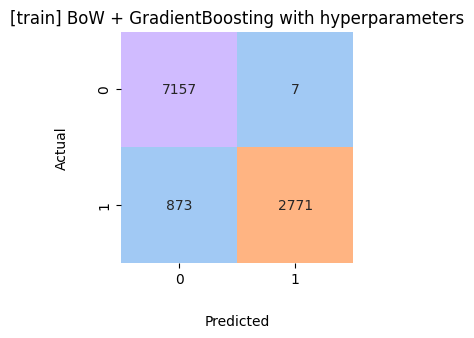

accuracy:	0.9185788304959289
precision:	0.9270879945509923
recall:		0.9185788304959289
f1:		0.9154093985415112


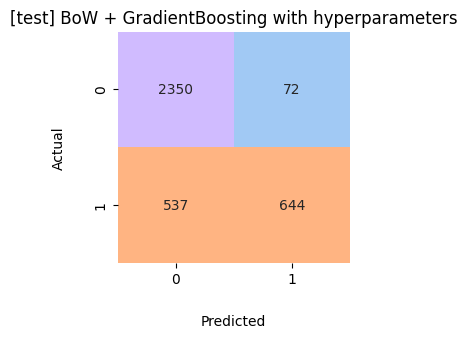

accuracy:	0.8309741881765196
precision:	0.8420019768712218
recall:		0.8309741881765196
f1:		0.817660298497388


In [35]:
y_pred = gb.predict(Xtrain_)
get_metrics(ytrain, y_pred, '[train] BoW + GradientBoosting with hyperparameters')
y_pred = gb.predict(Xtest_)
get_metrics(ytest, y_pred, '[test] BoW + GradientBoosting with hyperparameters')

In [36]:
y_prob = clf.predict_proba(Xtrain_)[:, 1]
print(f'roc_auc/train:\t{roc_auc_score(ytrain, y_prob)}')
y_prob = clf.predict_proba(Xtest_)[:, 1]
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

roc_auc/train:	0.9956264200009683
roc_auc/test:	0.8985182748318232


# BERT [roc-auc 0.93402]

In [37]:
df_train = pd.concat([Xtrain, ytrain.astype(int)], axis=1)
df_train

,comment,toxic
5049,козырёк второй фотка дешёвый сайдинг обшить вп...,1
4192,переключение поле ввод кнопка прочий интеракти...,0
10606,вокзал таксист очень сильно ценник упасть дешё...,0
9186,сколько угодный гундеть 43 маленький 50 любой ...,0
9971,запредельный цена питер москва лоукостер долет...,0
...,...,...
5191,знать откуда машина столько человек район новы...,0
13419,всё кроме тигр похожий обычный дворовый кот,0
5390,второй сезон полный хует,0
860,мда хотеть просто спасибо сказать обижёнка зад...,1


In [38]:
from torch.utils.data import Dataset


class TextClassificationDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        encoding = self.tokenizer(text, return_tensors='pt', max_length=self.max_length, padding='max_length', truncation=True)
        return {'input_ids': encoding['input_ids'].flatten(), 'attention_mask': encoding['attention_mask'].flatten(), 'label': torch.tensor(label)}

In [39]:
import torch
from torch import nn
from transformers import BertModel

class BERTClassifier(nn.Module):
    def __init__(self, bert_model_name, num_classes):
        super(BERTClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(bert_model_name)
        self.dropout = nn.Dropout(0.1)
        self.fc = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        pooled_output = outputs.pooler_output
        x = self.dropout(pooled_output)
        logits = self.fc(x)
        return logits

In [40]:
import os
from torch.utils.data import DataLoader
from transformers import BertTokenizer, get_linear_schedule_with_warmup
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm


def train(model, data_loader, optimizer, scheduler, device):
    model.train()
    for batch in tqdm(data_loader):
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = nn.CrossEntropyLoss()(outputs, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()


def evaluate(model, data_loader, device):
    model.eval()
    predictions = []
    actual_labels = []
    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            _, preds = torch.max(outputs, dim=1)
            predictions.extend(preds.cpu().tolist())
            actual_labels.extend(labels.cpu().tolist())
    return accuracy_score(actual_labels, predictions), classification_report(actual_labels, predictions)

In [41]:
features = ['comment', 'toxic']
texts = df_train['comment'].tolist()
labels = df_train['toxic'].tolist()


bert_model_name = 'cointegrated/rubert-tiny'
num_classes = 2
max_length = 128
batch_size = 16
num_epochs = 4
learning_rate = 2e-5

train_texts, val_texts, train_labels, val_labels = train_test_split(texts, labels, test_size=0.2, random_state=RANDOM_STATE)

tokenizer = BertTokenizer.from_pretrained(bert_model_name)
train_dataset = TextClassificationDataset(train_texts, train_labels, tokenizer, max_length)
val_dataset = TextClassificationDataset(val_texts, val_labels, tokenizer, max_length)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = BERTClassifier(bert_model_name, num_classes).to(device)

optimizer = AdamW(model.parameters(), lr=learning_rate)
total_steps = len(train_dataloader) * num_epochs
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

for epoch in range(num_epochs):
    print(f"Epoch {epoch + 1}/{num_epochs}")
    train(model, train_dataloader, optimizer, scheduler, device)
    accuracy, report = evaluate(model, val_dataloader, device)
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(report)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/241k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/468k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

... (6 outputs left out)

100%|██████████| 541/541 [08:20<00:00,  1.08it/s]


Validation Accuracy: 0.8626
              precision    recall  f1-score   support

           0       0.89      0.90      0.90      1436
           1       0.80      0.78      0.79       726

    accuracy                           0.86      2162
   macro avg       0.85      0.84      0.85      2162
weighted avg       0.86      0.86      0.86      2162

Epoch 4/4


100%|██████████| 541/541 [08:21<00:00,  1.08it/s]


Validation Accuracy: 0.8686
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1436
           1       0.80      0.81      0.81       726

    accuracy                           0.87      2162
   macro avg       0.85      0.85      0.85      2162
weighted avg       0.87      0.87      0.87      2162



In [42]:
torch.save(model.state_dict(), f'rubert-tiny-e4.pth')

In [43]:
def predict(text, model, tokenizer, device, max_length=128):
    model.eval()
    encoding = tokenizer(text, return_tensors='pt', max_length=max_length, padding='max_length', truncation=True)
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        _, preds = torch.max(outputs, dim=1)
    return 1 if preds.item() == 1 else 0


ypred = []
for comment in tqdm(Xtest['comment']):
    ypred.append(predict(comment, model, tokenizer, device))

100%|██████████| 3603/3603 [01:04<00:00, 55.76it/s]


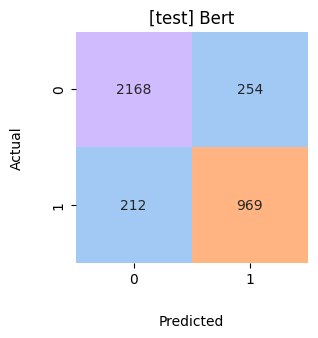

accuracy:	0.8706633361087982
precision:	0.8720459717693396
recall:		0.8706633361087982
f1:		0.871227536663773


In [44]:
get_metrics(ytest, ypred, '[test] Bert')

In [45]:
def predict_proba(text, model, tokenizer, device, max_length=128):
    model.eval()
    encoding = tokenizer(text, return_tensors='pt', max_length=max_length, padding='max_length', truncation=True)
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.softmax(outputs, dim=1)
    return preds[:, 1].item()


y_prob = []
for comment in tqdm(Xtest['comment']):
    y_prob.append(predict_proba(comment, model, tokenizer, device))
print(f'roc_auc/test:\t{roc_auc_score(ytest, y_prob)}')

100%|██████████| 3603/3603 [01:07<00:00, 53.76it/s]

roc_auc/test:	0.9333508601298708


# RL

## load seq2seq model

In [47]:
base_model_name = 'ai-forever/ruT5-base'
model_name = 's-nlp/ruT5-base-detox'

In [48]:
cache_dir = "D:/jupyter/" # fixes OSError: Unable to load vocabulary from file
cache_dir_tokenizers = cache_dir + "tokenizers/"
tokenizer = AutoTokenizer.from_pretrained(base_model_name, force_download=True, cache_dir=cache_dir_tokenizers)
model = T5ForConditionalGeneration.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/1.00M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/892M [00:00<?, ?B/s]

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
input_ids = tokenizer.encode('Это полная хуйня!', return_tensors='pt').to(device)
output_ids = model.generate(input_ids, max_length=50, num_return_sequences=1)
output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(output_text)

Это полная ерунда!


## prepare dataset

In [49]:
class CleanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        def clean_text(text):
            text = text.lower()
            text = re.sub(r'http\S+', '', text)
            text = re.sub(r'www\S+', '', text)
            text = re.sub(r"\'s", " ", text)
            text = re.sub('\W', ' ', text)
            text = re.sub('\s+', ' ', text)
            text = text.strip(' ')
            return text


        X_copy = X.copy()
        X_copy['comment'] = X_copy['comment'].apply(clean_text)
        return X_copy

In [50]:
df = pd.read_csv('comments.csv')
cleaner = CleanTransformer()
cleaner.fit(df)
df = cleaner.transform(df)
df = df[df['comment'] != '']
df = df[df['comment'].map(len) < 1000]
df

,comment,toxic
0,верблюдов то за что дебилы бл,1.0
1,хохлы это отдушина затюканого россиянина мол в...,1.0
2,собаке собачья смерть,1.0
3,страницу обнови дебил это тоже не оскорбление ...,1.0
4,тебя не убедил 6 страничный пдф в том что скри...,1.0
...,...,...
14407,вонючий совковый скот прибежал и ноет а вот и ...,1.0
14408,а кого любить гоблина тупорылого что ли или ка...,1.0
14409,посмотрел утомленных солнцем 2 и оказалось что...,0.0
14410,крымотред нарушает правила раздела т к в нем н...,1.0


In [51]:
RANDOM_STATE=42


X = df.drop(columns=['toxic'])
y = df['toxic']
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=RANDOM_STATE, test_size=0.25)
Xtrain.shape, Xtest.shape, ytrain.shape, ytest.shape

((10659, 1), (3554, 1), (10659,), (3554,))

In [52]:
ytrain.value_counts()

,count
toxic,
0.0,7071
1.0,3588


## initial detoxification model

In [53]:
# model.generate по батчам размера batch_size
def batch_generate(model, tokenizer, data, verbose=False, batch_size=100):
    n_batches = (data.shape[0] - 1) // batch_size + 1
    result = []
    pbar = range(n_batches)
    pbar = tqdm(pbar) if verbose else pbar
    model.eval()
    for i in pbar:
        batch = data.iloc[batch_size * i:batch_size * (i + 1)]

        with torch.no_grad():
            encoded = tokenizer(
                batch['comment'].tolist(),
                padding=True,
                truncation=True,
                return_tensors="pt",
                max_length=1000
            )
            input_ids = encoded['input_ids'].to(device)
            attention_mask = encoded['attention_mask'].to(device)

            output_ids = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_length=50,
                num_return_sequences=1
            )
            output_ids_cpu = output_ids.to('cpu')
            output_text = tokenizer.batch_decode(output_ids_cpu, skip_special_tokens=True)
            result.extend(output_text)

            del input_ids, attention_mask, output_ids_cpu, output_ids, encoded
            gc.collect()
            torch.cuda.empty_cache()
    return result

In [54]:
t = Xtrain[ytrain == 1.0].copy()

In [55]:
comments_detoxed = batch_generate(model, tokenizer, t, verbose=True, batch_size=200)

  0%|          | 0/18 [04:04<?, ?it/s]


KeyboardInterrupt: 

In [56]:
t['comment'] = comments_detoxed
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)
y_pred = lr_pipeline.predict(lemmatizer.transform(t))

NameError: name 'comments_detoxed' is not defined

In [ ]:
# количество токсичных комментариев до и после детоксификации по версии нашей модели
print(f'before:\t{t.shape[0]}')
print(f'after:\t{y_pred.sum()}')

before:	3588
after:	2392.0


In [ ]:
y_pred = lr_pipeline.predict_proba(lemmatizer.transform(t))[:, 1]
Xtrain_with_pred = Xtrain[ytrain == 1.0].copy()
Xtrain_with_pred['prediction'] = y_pred
Xtrain_with_pred

,comment,prediction
2283,у ух ненавижу блядь хохлов,0.903383
3657,модератор не мой я просто разместил объяву,0.540758
8230,ну я бы не сказал что ее пиарили больше чем то...,0.568804
14302,связаны даун читать то умеешь,0.638549
2462,ну так и задайся вопросом петух ты ущербный по...,0.677058
...,...,...
5688,мне еще не отсосал скот губастенький,0.696787
13707,срочно сообщите достоевскому что он хохол вот ...,0.752769
6391,бляяяя какой же люмпенский ебасос у него,0.487921
5849,в двух словах работы колмогорова безграмотной ...,0.859789


In [ ]:
Xtrain_with_pred['prediction'].describe()

count    3588.000000
mean        0.606108
std         0.236591
min         0.000113
25%         0.437166
50%         0.619928
75%         0.801434
max         1.000000
Name: prediction, dtype: float64

In [ ]:
# используем предсказания модели без дообучения для подсчета reward
class ToxicDataset(torch.utils.data.Dataset):
    def __init__(self, X):
        super().__init__()
        self.X = X

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, index: int):
        return {'query': self.X['comment'].iloc[index],
                'input_ids': torch.tensor(tokenizer.encode(X['comment'].iloc[index])),
                'prediction': self.X['prediction'].iloc[index]}

In [ ]:
toxic_dataset = ToxicDataset(Xtrain_with_pred)
toxic_dataset[0]

{'query': 'у ух ненавижу блядь хохлов',
 'input_ids': tensor([24839,    36,    62,    22,    16,   579,  2097,    19, 13103,     2]),
 'prediction': 0.903383061039633}

## ppo training

In [57]:
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)


# считаем разницу между предсказанием без дообучения и предсказанием с дообучением
def compute_reward(texts: List[str], predictions) -> torch.Tensor:
    t = lemmatizer.transform(texts)
    new_predictions = lr_pipeline.predict_proba(pd.DataFrame(t, columns=['comment']))[:, 1]
    return torch.tensor(predictions - new_predictions)

LookupError: 
**********************************************************************
  Resource [93mstopwords[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('stopwords')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mcorpora/stopwords[0m

  Searched in:
    - '/root/nltk_data'
    - '/usr/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [ ]:
# better results (new predictions fixed toxicity)
texts = Xtrain[ytrain == 0]['comment'].head(5).values.tolist()
print(compute_reward(texts, [1] * 5))

# same results (new predictions have the same toxicity)
texts = Xtrain[ytrain == 0]['comment'].head(5).values.tolist()
print(compute_reward(texts, [0] * 5))
texts = Xtrain[ytrain == 1]['comment'].head(5).values.tolist()
print(compute_reward(texts, [1] * 5))

# bad results (new predictions are more toxic)
texts = Xtrain[ytrain == 1]['comment'].head(5).values.tolist()
print(compute_reward(texts, [0] * 5))

tensor([0.9623, 1.0000, 0.8878, 0.9757, 0.9999], dtype=torch.float64)
tensor([-3.7685e-02, -5.1091e-09, -1.1221e-01, -2.4272e-02, -5.1901e-05],
       dtype=torch.float64)
tensor([0.0012, 0.4592, 0.2037, 0.1096, 0.0041], dtype=torch.float64)
tensor([-0.9988, -0.5408, -0.7963, -0.8904, -0.9959], dtype=torch.float64)


In [ ]:
[toxic_dataset[i]['prediction'] for i in range(5)]

[0.903383061039633,
 0.5407575038205545,
 0.5688042732620234,
 0.6385491339366679,
 0.6770577977018263]

In [ ]:
compute_reward([toxic_dataset[i]['query'] for i in range(5)], [1] * 5)

tensor([0.0012, 0.4592, 0.2037, 0.1096, 0.0041], dtype=torch.float64)

In [ ]:
peft_config = peft.LoraConfig(
    task_type=peft.TaskType.CAUSAL_LM, r=32, lora_alpha=32, lora_dropout=0.0, inference_mode=False
)

main_tokenizer = tokenizer
main_tokenizer.pad_token = main_tokenizer.eos_token

main_model = trl.AutoModelForSeq2SeqLMWithValueHead.from_pretrained(model_name, device_map=device)
main_model = peft.get_peft_model(main_model, peft_config, adapter_name='default')
main_model.print_trainable_parameters()

trainable params: 3,538,944 || all params: 226,443,265 || trainable%: 1.562839150901662


In [ ]:
training_args = trl.PPOConfig(
    model_name=main_model.config._name_or_path,
    gradient_accumulation_steps=1,
    learning_rate=1.41e-5,
    batch_size=32,
    ppo_epochs=6,
)

ppo_trainer = trl.PPOTrainer(
    training_args, model=main_model.model, tokenizer=main_tokenizer,
    dataset=toxic_dataset, data_collator=lambda data: dict((key, [d[key] for d in data]) for key in data[0])
)

In [ ]:
max_steps = 30
generation_kwargs = dict(max_length=50, num_return_sequences=1)

with tqdm(enumerate(ppo_trainer.dataloader), total=max_steps) as progressbar:
  for epoch, batch in progressbar:
    if epoch >= max_steps:
        break

    response_tensors = ppo_trainer.generate(batch['input_ids'], **generation_kwargs)

    batch['response'] = [main_tokenizer.decode(response.squeeze()) for response in response_tensors]

    rewards = compute_reward(batch['response'], batch['prediction'])
    print("REWARD SAMPLE:", rewards[:5])

    stats = ppo_trainer.step(batch['input_ids'], response_tensors, list(rewards.split(1)))
    stats['rewards/mean'] = rewards.mean().item()

    print("-" * 30, 'STEP', epoch, '-' * 30)
    print(f'rewards/mean:\t{stats["rewards/mean"]:.9f}\t<---- average reward over this batch (higher=better, noisy)')
    print(f'ppo/returns/mean:\t{stats["ppo/returns/mean"]:.9f}\t<---- model-estimated average discounted reward')
    print(f'objective/kl:\t{stats["objective/kl"]:.9f}\t<---- how far we are from the original model (regularizer)')
    print()

    ppo_trainer.log_stats(stats, batch, list(rewards.split(1)))

  0%|                                                                                                                                                                                     | 0/30 [00:00<?, ?it/s]

REWARD SAMPLE: tensor([-0.0397,  0.5632, -0.2035,  0.2662,  0.7135], dtype=torch.float64)


  3%|█████▊                                                                                                                                                                       | 1/30 [00:38<18:34, 38.42s/it]

------------------------------ STEP 0 ------------------------------
rewards/mean:	0.200367848	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	0.079429388	<---- model-estimated average discounted reward
objective/kl:	0.000000000	<---- how far we are from the original model (regularizer)

REWARD SAMPLE: tensor([ 0.6675, -0.0114,  0.1859,  0.2688, -0.3012], dtype=torch.float64)


  7%|███████████▌                                                                                                                                                                 | 2/30 [01:16<17:54, 38.38s/it]

------------------------------ STEP 1 ------------------------------
rewards/mean:	0.159266016	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	-0.060347065	<---- model-estimated average discounted reward
objective/kl:	0.924896777	<---- how far we are from the original model (regularizer)

REWARD SAMPLE: tensor([0.5139, 0.2982, 0.4647, 0.3361, 0.6334], dtype=torch.float64)


... (52 outputs left out)

 97%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▎     | 29/30 [18:31<00:37, 37.89s/it]

------------------------------ STEP 28 ------------------------------
rewards/mean:	0.154373153	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	-0.089849412	<---- model-estimated average discounted reward
objective/kl:	2.969680786	<---- how far we are from the original model (regularizer)

REWARD SAMPLE: tensor([-0.4005, -0.2012, -0.1496,  0.6206,  0.4193], dtype=torch.float64)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [19:09<00:00, 38.33s/it]

------------------------------ STEP 29 ------------------------------
rewards/mean:	0.303517327	<---- average reward over this batch (higher=better, noisy)
ppo/returns/mean:	-0.231063336	<---- model-estimated average discounted reward
objective/kl:	3.917632818	<---- how far we are from the original model (regularizer)



### Save model

In [ ]:
main_model_merged = main_model.merge_and_unload()
main_model_merged.save_pretrained('hse-toxic-50')

## after rl

### Load model

In [ ]:
tuned_model = AutoModelForSeq2SeqLM.from_pretrained('hse-toxic-50', local_files_only=True)
tuned_model = tuned_model.to(device)

Some weights of the model checkpoint at hse-toxic-50 were not used when initializing T5ForConditionalGeneration: ['v_head.summary.bias', 'v_head.summary.weight']
- This IS expected if you are initializing T5ForConditionalGeneration from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing T5ForConditionalGeneration from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
input_ids = tokenizer.encode('Это полная хуйня!', return_tensors='pt').to(device)
output_ids = tuned_model.generate(input_ids, max_length=50, num_return_sequences=1)
output_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)
print(output_text)

Это полная ерунда!


### Use model

In [ ]:
t = Xtrain[ytrain == 1.0].copy()

In [ ]:
comments_detoxed = batch_generate(tuned_model, tokenizer, t, verbose=True, batch_size=200)
# comments_detoxed = batch_generate(main_model.model, tokenizer, Xtest, verbose=True, batch_size=200)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [00:47<00:00,  2.62s/it]


In [ ]:
# k = 10
# t = Xtest.reset_index(drop=True)[ytest.reset_index(drop=True) == 1.0]['comment'].sample(5, random_state=0)
# list(zip(t.values.tolist(), np.array(comments_detoxed)[t.index.values.tolist()]))

In [ ]:
t['comment'] = comments_detoxed
lemmatizer = LemmatizeTransformer()
lemmatizer.fit(df)
y_pred = lr_pipeline.predict(lemmatizer.transform(t))

In [ ]:
# количество токсичных комментариев до и после детоксификации по версии модели
print(f'before:\t{t.shape[0]}')
print(f'after:\t{y_pred.sum()}')

before:	3588
after:	2441.0


До RL модель оставляла 2392 токсичных комментария, похоже стало хуже(